# 07 · Monitoring: Data Quality, Model Quality, Dashboards and Retraining

1. **Model Monitor baseline** (statistics + constraints) from the training split's tabular features.
2. **Data-quality checks** with the Model Monitor analyzer: (a) the real incoming batch; (b) a simulated
   *degraded upstream* batch (truncated LLM copy and a pricing bug) to show violations.
3. **Drift (PSI)** per feature, and **model quality** from batch outputs, both published to **CloudWatch**.
4. **CloudWatch dashboard** with infrastructure (job CPU/memory) and model/business metrics.
5. **Retraining trigger:** a CloudWatch alarm plus EventBridge rule, and a programmatic trigger that starts the pipeline.

In [1]:
# Pin the SageMaker SDK v2 API used by this project (no-op if already installed)
%pip install -q "sagemaker>=2.232,<3"

Note: you may need to restart the kernel to use updated packages.


In [2]:
import os
import sys
import warnings

warnings.filterwarnings("ignore")
def find_repo_root():
    """The notebooks import from src/, so the whole repo must be cloned, not just notebooks/."""
    candidates = [os.path.expanduser("~/steam-store-copilot")]
    try:  # the kernel's working directory may have been deleted (e.g. after re-cloning)
        candidates = [os.getcwd(), os.path.dirname(os.getcwd())] + candidates
    except FileNotFoundError:
        os.chdir(os.path.expanduser("~"))
    for path in candidates:
        if os.path.isdir(os.path.join(path, "src")) and os.path.exists(os.path.join(path, "src", "config.py")):
            return path
    raise RuntimeError("Could not find the repo's src/ folder. Clone the full repository in Studio "
                       "(Git > Clone Repository) and open the notebooks from steam-store-copilot/notebooks/.")


REPO_ROOT = find_repo_root()
if REPO_ROOT not in sys.path:
    sys.path.insert(0, REPO_ROOT)
print("Repo root:", REPO_ROOT)

import logging

for _name in ("sagemaker", "sagemaker.config", "botocore.credentials"):
    logging.getLogger(_name).setLevel(logging.ERROR)  # keep SDK log noise out of the outputs

import boto3
import sagemaker

from src.config import S3Layout

# Works both inside SageMaker Studio and on a laptop with Learner Lab credentials in ~/.aws/credentials
boto_session = boto3.Session(region_name=boto3.Session().region_name or "us-east-1")
sess = sagemaker.Session(boto_session=boto_session)
region = sess.boto_region_name
if os.path.exists("/opt/ml/metadata/resource-metadata.json"):  # inside SageMaker Studio
    role = sagemaker.get_execution_role(sagemaker_session=sess)
else:  # laptop with Learner Lab credentials: jobs run as the lab's execution role
    account = boto_session.client("sts").get_caller_identity()["Account"]
    role = f"arn:aws:iam::{account}:role/LabRole"
layout = S3Layout(bucket=sess.default_bucket())
sm = boto3.client("sagemaker", region_name=region)
print("Region:", region)
print("Role:  ", role)
print("Bucket:", layout.bucket)

Repo root: /Users/yatharthvardan/Documents/USD/steam-store-copilot


Region: us-east-1
Role:   arn:aws:iam::326278567375:role/LabRole
Bucket: sagemaker-us-east-1-326278567375


In [3]:
import json

import matplotlib.pyplot as plt
import pandas as pd

from src.config import PIPELINE_NAME, TAG_GATE_MODEL_GROUP
from src.data.s3io import read_csv, read_text, write_csv
from src.monitoring import dashboard, retrain
from src.monitoring import data_quality as dq
from src.monitoring.model_quality import publish_metrics

cw = boto3.client("cloudwatch", region_name=region)
execs = sm.list_pipeline_executions(PipelineName=PIPELINE_NAME, SortBy="CreationTime",
                                    SortOrder="Descending")["PipelineExecutionSummaries"]
last_ok = next(e for e in execs if e["PipelineExecutionStatus"] == "Succeeded")
execution_id = last_ok["PipelineExecutionArn"].split("/")[-1]
train_features_uri = f"{layout.pipeline_artifacts}/{execution_id}/data/monitor/train_features.csv"
batch_prefix = read_text(f"{layout.batch}/LATEST").strip()
baseline_uri = f"{layout.monitoring}/baseline"
print("Baseline data:", train_features_uri)
print("Latest batch: ", batch_prefix)

Baseline data: s3://sagemaker-us-east-1-326278567375/steam-store-copilot/pipeline/bvdmk3bbbekl/data/monitor/train_features.csv
Latest batch:  s3://sagemaker-us-east-1-326278567375/steam-store-copilot/batch/20261017-180846


## 1. Model Monitor baseline

In [4]:
monitor = dq.suggest_baseline(role, train_features_uri, baseline_uri, sess)
stats = json.loads(read_text(f"{baseline_uri}/statistics.json"))
constraints = json.loads(read_text(f"{baseline_uri}/constraints.json"))
pd.DataFrame([{"feature": f["name"], "type": f["inferred_type"],
               "mean": f.get("numerical_statistics", {}).get("mean"),
               "std": f.get("numerical_statistics", {}).get("std_dev"),
               "completeness": constraints["features"][i].get("completeness")}
              for i, f in enumerate(stats["features"])]).round(3)

.

.

.

.

.

...

.

.

.

!

,feature,type,mean,std,completeness
0,price,Fractional,5.075,12.245,1.0
1,required_age,Integral,0.230,1.931,1.0
2,desc_chars,Integral,1316.381,1002.170,1.0
3,desc_words,Integral,220.066,167.097,1.0
4,windows,Integral,1.000,0.014,1.0
5,mac,Integral,0.204,0.403,1.0
6,linux,Integral,0.143,0.350,1.0
7,n_tags_22,Integral,5.448,2.304,1.0


## 2. Data-quality checks
(a) the real incoming batch, and (b) a degraded copy that simulates an upstream failure.

In [5]:
incoming = read_csv(f"{batch_prefix}/monitor/features.csv")
degraded = incoming.copy()
degraded["desc_chars"] = (degraded["desc_chars"] * 0.2).round()      # truncated LLM output
degraded["desc_words"] = (degraded["desc_words"] * 0.2).round()
degraded["price"] = degraded["price"] * 100                           # cents-vs-dollars bug
degraded.loc[degraded.sample(frac=0.3, random_state=0).index, "required_age"] = -1
degraded_uri = write_csv(degraded, f"{batch_prefix}/monitor_degraded/features.csv", index=False)

reports = {}
for name, uri in {"incoming": f"{batch_prefix}/monitor/", "degraded": f"{batch_prefix}/monitor_degraded/"}.items():
    out = f"{layout.monitoring}/reports/{batch_prefix.split('/')[-1]}/{name}"
    dq.run_data_quality_check(role, uri, baseline_uri, out, sess)
    try:
        reports[name] = json.loads(read_text(f"{out}/constraint_violations.json")).get("violations", [])
    except Exception:
        reports[name] = []
    print(f"{name:<9} -> {len(reports[name])} Model Monitor violations")

.

.

.

.

.

...

.

.

.

!

degraded  -> 3 Model Monitor violations


In [6]:
pd.DataFrame([{"batch": b, **v} for b, vs in reports.items() for v in vs])

,batch,feature_name,constraint_check_type,description
0,incoming,price,baseline_drift_check,Baseline drift distance: 0.1013820787707554 ex...
1,degraded,desc_words,data_type_check,Data type match requirement is not met. Expect...
2,degraded,desc_chars,data_type_check,Data type match requirement is not met. Expect...
3,degraded,price,baseline_drift_check,Baseline drift distance: 0.9057689855980036 ex...


## 3. Drift (PSI) and model quality to CloudWatch

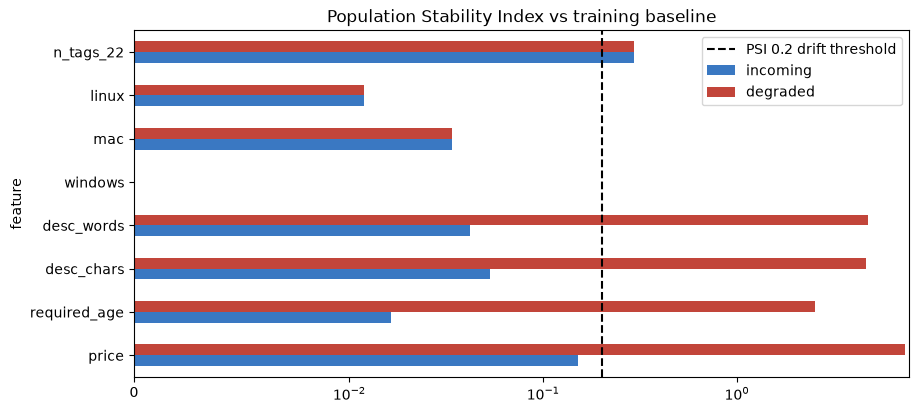

,incoming,degraded
feature,,
price,0.152,7.344
required_age,0.016,2.521
desc_chars,0.053,4.617
desc_words,0.042,4.718
windows,0.000,0.000
mac,0.034,0.034
linux,0.012,0.012
n_tags_22,0.294,0.294


In [7]:
baseline_df = read_csv(train_features_uri)
psi = {name: dq.psi_report(baseline_df, df) for name, df in {"incoming": incoming, "degraded": degraded}.items()}
psi_table = pd.concat({k: v.set_index("feature")["psi"] for k, v in psi.items()}, axis=1)
ax = psi_table.plot.barh(figsize=(10, 4.5), color=["#3a78c2", "#c2453a"])
ax.axvline(0.2, color="k", ls="--", label="PSI 0.2 drift threshold")
ax.set_xscale("symlog", linthresh=0.01)
ax.legend()
ax.set_title("Population Stability Index vs training baseline")
plt.show()
psi_table.round(3)

In [8]:
quality = json.loads(read_text(f"{batch_prefix}/quality.json"))
for name in ("incoming", "degraded"):
    drifted = psi[name].query("drift")["feature"].tolist()
    metrics = {"drifted_features": len(drifted), "dq_violations": len(reports[name])}
    if name == "incoming":
        metrics.update(quality)
    publish_metrics(metrics, {"Model": "tag-gate"} if name == "incoming" else {"Model": "tag-gate-degraded-sim"}, cw)
    print(name, metrics)

incoming {'drifted_features': 1, 'dq_violations': 1, 'records': 5855, 'macro_f1': 0.6347977758725989, 'auto_approval_rate': 0.44796573875803, 'false_approval_rate': 0.038593481989708404, 'human_review_rate': 0.0032450896669513236}
degraded {'drifted_features': 5, 'dq_violations': 3}


## 4. CloudWatch dashboard

In [9]:
url = dashboard.put_dashboard(cw, region)
print("Dashboard:", url)

Dashboard: https://us-east-1.console.aws.amazon.com/cloudwatch/home?region=us-east-1#dashboards:name=SteamStoreCopilot


## 5. Retraining trigger
The reference macro-F1 comes from the registered model's evaluation report.

In [10]:
latest_pkg = sm.list_model_packages(ModelPackageGroupName=TAG_GATE_MODEL_GROUP, ModelApprovalStatus="Approved",
                                    SortBy="CreationTime", SortOrder="Descending")["ModelPackageSummaryList"][0]
detail = sm.describe_model_package(ModelPackageName=latest_pkg["ModelPackageArn"])
evaluation = json.loads(read_text(detail["ModelMetrics"]["ModelQuality"]["Statistics"]["S3Uri"]))
reference_f1 = evaluation["tag_gate"]["macro_f1"]["value"]

decisions = {
    "incoming": retrain.should_retrain(psi["incoming"].query("drift")["feature"].tolist(), len(reports["incoming"]),
                                       quality, reference_f1),
    "degraded": retrain.should_retrain(psi["degraded"].query("drift")["feature"].tolist(), len(reports["degraded"]),
                                       {}, reference_f1),
}
for name, d in decisions.items():
    print(f"{name:<9} retrain={d.retrain}  reasons={d.reasons}")

incoming  retrain=True  reasons=['feature drift (PSI>0.2): n_tags_22', '1 Model Monitor data-quality violations']
degraded  retrain=True  reasons=['feature drift (PSI>0.2): price, required_age, desc_chars, desc_words, n_tags_22', '3 Model Monitor data-quality violations']


In [11]:
execution_arn = retrain.trigger_retraining(sm, decisions["degraded"])
execution_arn

Retraining started: arn:aws:sagemaker:us-east-1:326278567375:pipeline/steam-tag-gate-pipeline/execution/68zq2yrhep7c


'arn:aws:sagemaker:us-east-1:326278567375:pipeline/steam-tag-gate-pipeline/execution/68zq2yrhep7c'

In [12]:
pipeline_arn = sm.describe_pipeline(PipelineName=PIPELINE_NAME)["PipelineArn"]
try:
    retrain.create_alarm_and_rule(cw, boto3.client("events", region_name=region), pipeline_arn, role)
    print("CloudWatch alarm 'steam-tag-gate-drift' + EventBridge rule 'steam-tag-gate-retrain-on-drift' created.")
except Exception as exc:  # Learner Lab may restrict EventBridge targets
    print("Alarm/rule wiring not permitted in this account:", exc)
    print("The programmatic trigger above is the retraining path in this environment.")

CloudWatch alarm 'steam-tag-gate-drift' + EventBridge rule 'steam-tag-gate-retrain-on-drift' created.
